# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ.** Полный прогон сделан на Apple M4 (MPS) с `FAST_MODE = False`. Датасет — Oxford-IIIT Pet (CC BY-SA 4.0), 400 снимков в train и по 100 в val и test. Функции оценки и запуска обучения взяты из шаблона, модель — из Ultralytics. Из бонусов выполнены 6.3–6.5. Эксперименты с ручной разметкой и RT-DETR не запускались.

In [1]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.4.0,<8.5'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

ultralytics 8.4.216, torch 2.15.0, device: mps


In [2]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.3', '6.4', '6.5'}     # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [3]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [4]:
WEIGHTS = 'yolo26n.pt'   # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)
# ваш код
param_count = sum(p.numel() for p in model_coco.model.parameters())
n_coco = len(model_coco.names)
dummy_img = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)

def sync_device():
    if isinstance(DEVICE, int):
        torch.cuda.synchronize(DEVICE)
    elif DEVICE == 'mps':
        torch.mps.synchronize()

predict_args = dict(imgsz=IMGSZ, device=DEVICE, verbose=False)
for _ in range(3):
    model_coco.predict(dummy_img, **predict_args)
sync_device()
start = time.perf_counter()
for _ in range(12):
    model_coco.predict(dummy_img, **predict_args)
    sync_device()
latency_ms = (time.perf_counter() - start) * 1000 / 12
MODEL_INFO = dict(ultralytics=ultralytics.__version__, weights=weights_path.name,
                  sha256=hashlib.sha256(weights_path.read_bytes()).hexdigest(),
                  size_mb=weights_path.stat().st_size / 1_000_000,
                  params=param_count, n_classes_coco=n_coco, latency_ms=latency_ms)

In [5]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.216',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.544453,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 10.452642333499776}

**Ответ.** Для 400 обучающих снимков взяла YOLO26n, чтобы уложиться в бюджет и успеть повторить обучение для абляции. В таблице у n и s соответственно 2.4 и 9.5 млн параметров после слияния, end-to-end mAP50–95 на COCO 40.1% и 47.8%, задержка на T4 (TensorRT10) 1.7 и 2.5 мс. В прогоне `yolo26n.pt` весит 5.54 МБ, в полном checkpoint 2 572 280 параметров, а `predict` при 640×640 на MPS занял в среднем 10.45 мс. Код и веса доступны по AGPL-3.0 или коммерческой лицензии. AGPL требует предоставить соответствующие исходники при распространении, а для изменённой версии, доступной по сети, также дать доступ к исходникам её сетевым пользователям.

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [6]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model                     # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone'])  # первые n_backbone слоев - backbone, последний - Detect
    # ваш код
    return {
        'backbone': sum(p.numel() for p in layers[:n_backbone].parameters()),
        'neck': sum(p.numel() for p in layers[n_backbone:-1].parameters()),
        'head': sum(p.numel() for p in layers[-1].parameters()),
    }


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    # ваш код
    feature_shapes = []

    def capture_inputs(module, args):
        feature_shapes.extend(tuple(feature.shape) for feature in args[0])

    parameter = next(det_model.parameters())
    training_states = [(module, module.training) for module in det_model.modules()]
    handle = det_model.model[-1].register_forward_pre_hook(capture_inputs)
    try:
        det_model.eval()
        with torch.inference_mode():
            output = det_model(parameter.new_zeros((1, 3, imgsz, imgsz)))
    finally:
        handle.remove()
        for module, training in training_states:
            module.training = training
    return feature_shapes, output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [7]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [8]:
# ваш код
print('Выход Detect:', shapes(out))

Выход Detect: [(1, 84, 8400), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]


**Ответ.** Backbone извлекает признаки, neck объединяет признаки разных разрешений, а Detect предсказывает 4 координаты бокса и оценки 80 классов COCO на каждой позиции. Карты при входе 640×640 имеют размеры 64×80×80, 128×40×40 и 256×20×20 без оси батча. При stride 8, 16 и 32 получается 80² + 40² + 20² = 8400 позиций. Модель anchor-free, потому что бокс предсказывается относительно точки сетки без заранее заданной ширины и высоты. При обучении `one2many` назначает несколько предсказаний одному объекту, а `one2one` одно, поэтому в end-to-end режиме можно использовать `one2one` без NMS. На backbone приходится 53% параметров, на neck 35%, на Detect 12%.

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [9]:
# ваш код
from IPython.display import display, Markdown

CLASSES = ['cat_head', 'dog_head']
DATASET_NAME = 'Oxford-IIIT Pet, https://www.robots.ox.ac.uk/~vgg/data/pets/, CC BY-SA 4.0'
dataset = torchvision.datasets.OxfordIIITPet(root=DATA_ROOT, split='trainval', download=True)
pet_root = DATA_ROOT / 'oxford-iiit-pet'
annotation_root = pet_root / 'annotations'
pools = {0: [], 1: []}
clipped = dropped = without_xml = 0

for line in (annotation_root / 'trainval.txt').read_text().splitlines():
    image_id, _, species, _ = line.split()
    xml_path = annotation_root / 'xmls' / f'{image_id}.xml'
    if not xml_path.is_file():
        without_xml += 1
        continue
    image_path = pet_root / 'images' / f'{image_id}.jpg'
    with Image.open(image_path) as image:
        width, height = image.size
    boxes = []
    for box in ET.parse(xml_path).getroot().findall('object/bndbox'):
        coords = np.array([float(box.findtext(key)) for key in ('xmin', 'ymin', 'xmax', 'ymax')])
        coords[:2] -= 1  # VOC: начало пиксельных координат с единицы
        clean = np.clip(coords, 0, [width, height, width, height])
        clipped += int(np.any(clean != coords))
        if np.any(clean[2:] <= clean[:2]):
            dropped += 1
            continue
        boxes.append(clean)
    if boxes:
        label = int(species) - 1
        pools[label].append(dict(image=image_path, width=width, height=height,
                                 boxes=np.array(boxes, dtype=np.float32),
                                 labels=np.full(len(boxes), label, dtype=np.int64)))

records = {split: [] for split in ('train', 'val', 'test')}
split_rng = np.random.default_rng(SEED)
for pool in pools.values():
    assert len(pool) >= 300
    selected = [pool[i] for i in split_rng.permutation(len(pool))[:300]]
    records['train'].extend(selected[:200])
    records['val'].extend(selected[200:250])
    records['test'].extend(selected[250:])
for split_records in records.values():
    split_rng.shuffle(split_records)
print(f'Обрезано боксов: {clipped}, удалено: {dropped}, без XML: {without_xml}')

Обрезано боксов: 0, удалено: 0, без XML: 9


In [10]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 400, 'val': 100, 'test': 100}

train 400 {'cat_head': np.int64(200), 'dog_head': np.int64(200)} объектов на фото: 1.00; максимум: 1
  медианная доля площади: 15.7%; боксов меньше 5% площади: 7.5%
val 100 {'cat_head': np.int64(50), 'dog_head': np.int64(50)} объектов на фото: 1.00; максимум: 1
  медианная доля площади: 17.8%; боксов меньше 5% площади: 4.0%
test 100 {'cat_head': np.int64(50), 'dog_head': np.int64(50)} объектов на фото: 1.00; максимум: 1
  медианная доля площади: 14.1%; боксов меньше 5% площади: 9.0%


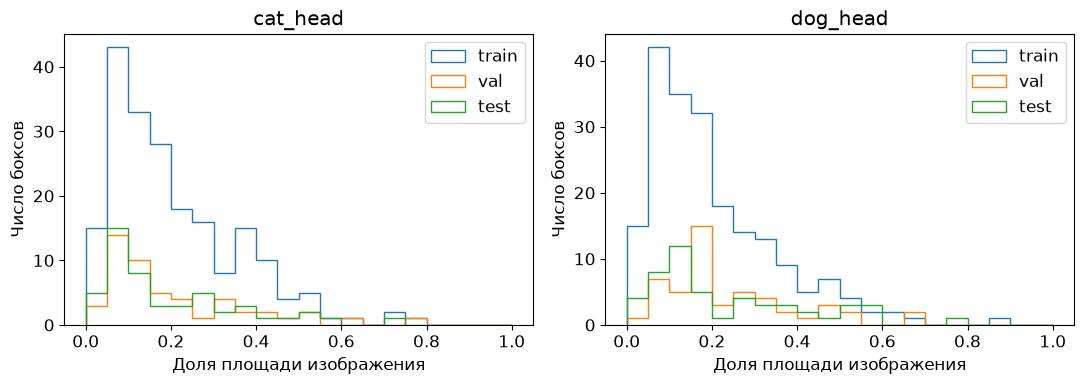

In [11]:
# ваш код
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for split, split_records in records.items():
    counts = [len(r['boxes']) for r in split_records]
    labels = np.concatenate([r['labels'] for r in split_records])
    print(split, len(split_records), dict(zip(CLASSES, np.bincount(labels, minlength=len(CLASSES)))),
          f'объектов на фото: {np.mean(counts):.2f}; максимум: {max(counts)}')
    areas = np.concatenate([np.prod(r['boxes'][:, 2:] - r['boxes'][:, :2], axis=1)
                            / (r['width'] * r['height']) for r in split_records])
    print(f'  медианная доля площади: {np.median(areas):.1%}; боксов меньше 5% площади: {np.mean(areas < .05):.1%}')
    for label, ax in enumerate(axes):
        ax.hist(areas[labels == label], bins=np.linspace(0, 1, 21), histtype='step', label=split)
        ax.set(title=CLASSES[label], xlabel='Доля площади изображения', ylabel='Число боксов')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

**Ответ.** Из официального `trainval` взяла по 300 снимков кошек и собак с VOC XML (seed = 0) и разделила их на 400/100/100. В каждом сплите по одной размеченной голове на снимок и поровну объектов двух классов. Медианная площадь рамки на train, val и test 15.7%, 17.8% и 14.1% кадра. Боксов меньше 5% площади больше всего на test (9% против 4% на val). У 9 снимков не было XML, а среди прочитанных боксов обрезанных или вырожденных не оказалось.

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [12]:
def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, координаты в [0, 1]
    # ваш код
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4) / [width, height, width, height]
    centers = (boxes[:, :2] + boxes[:, 2:]) / 2
    sizes = boxes[:, 2:] - boxes[:, :2]
    return '\n'.join(f'{int(label)} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}'
                     for label, (cx, cy), (w, h) in zip(labels, centers, sizes))


def from_yolo(text, width, height):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    # ваш код
    rows = np.array([line.split() for line in text.splitlines() if line.strip()],
                    dtype=float).reshape(-1, 5)
    center = rows[:, 1:3]
    half_size = rows[:, 3:5] / 2
    boxes = np.concatenate([center - half_size, center + half_size], axis=1)
    boxes *= [width, height, width, height]
    return boxes.astype(np.float32), rows[:, 0].astype(np.int64)

In [13]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [14]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    # ваш код
    image_dir = YOLO_ROOT / 'images' / split
    label_dir = YOLO_ROOT / 'labels' / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    for record in recs:
        image = Path(record['image'])
        shutil.copy2(image, image_dir / image.name)
        label_path = label_dir / f'{image.stem}.txt'
        label_path.write_text(to_yolo(record['boxes'], record['labels'],
                                      record['width'], record['height']), encoding='utf-8')


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: /Users/lizadyachkova/yolo-hw2/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: cat_head
  1: dog_head



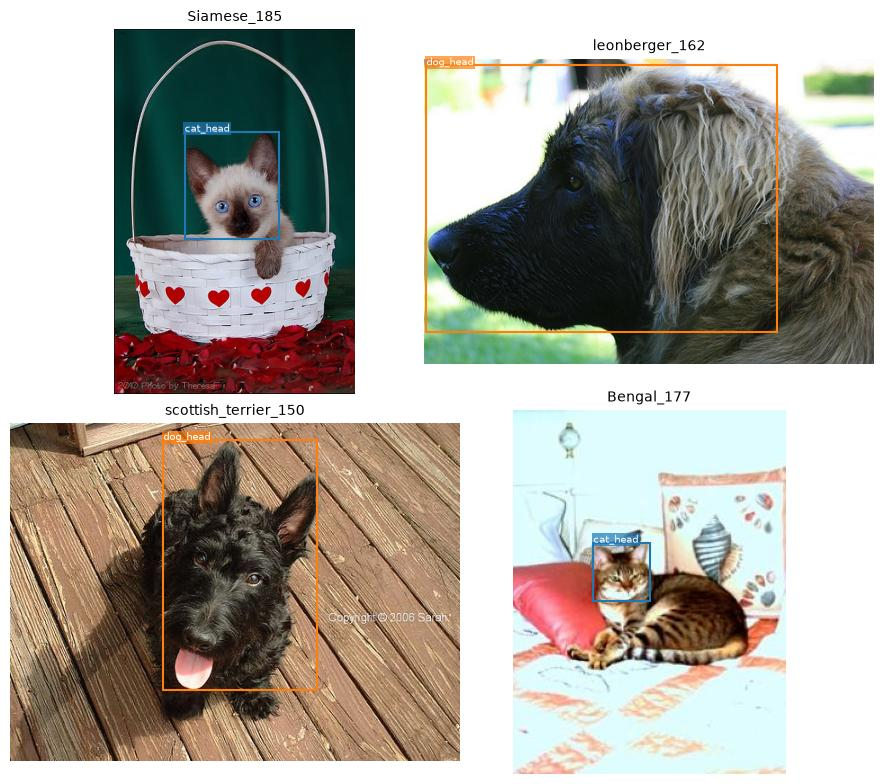

In [15]:
# ваш код
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, record in zip(axes.flat, records['val'][:4]):
    path = Path(record['image'])
    label_path = YOLO_ROOT / 'labels' / 'val' / f'{path.stem}.txt'
    boxes, labels = from_yolo(label_path.read_text(), record['width'], record['height'])
    assert np.array_equal(labels, record['labels'])
    assert np.allclose(boxes, record['boxes'], atol=1e-6 * max(record['width'], record['height']))
    with Image.open(path) as image:
        draw_boxes(ax, image.convert('RGB'), boxes, labels, CLASSES, title=path.stem)
plt.tight_layout()
plt.show()

**Ответ.** Проверка `to_yolo` → `from_yolo` прошла: классы совпали, а координаты восстановились с допуском на округление. Если в обеих функциях одинаково перепутать ширину и высоту, round-trip всё равно может пройти. Поэтому я ещё прочитала 4 экспортированных файла и наложила боксы на фото, так станвоится видно, попадает ли рамка на голову и нет ли сдвига.

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

In [16]:
# ваш код
evaluation_records = records[FINAL_SPLIT]
coco_names = model_coco.names
mapping = {idx: CLASSES.index(f'{name}_head') for idx, name in coco_names.items()
           if f'{name}_head' in CLASSES}
start = time.perf_counter()
coco_preds = predict_records(model_coco, evaluation_records, batch=BATCH, classes=list(mapping))
RUN_TIMES['coco'] = time.perf_counter() - start
for prediction in coco_preds:
    prediction['labels'] = np.array([mapping[i] for i in prediction['labels']], dtype=np.int64)
coco_map50, coco_aps = evaluate_map50(coco_preds, evaluation_records, len(CLASSES))
print(f'COCO mAP50: {coco_map50:.4f}', dict(zip(CLASSES, coco_aps)))

COCO mAP50: 0.0808 {'cat_head': 0.0696, 'dog_head': 0.09203368226183886}


In [17]:
def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей
    # ваш код
    with Image.open(image_path) as image:
        width, height = image.size
    boxes = template_boxes * [width, height, width, height]
    return dict(boxes=boxes, scores=template_scores.copy(),
                labels=np.arange(len(CLASSES), dtype=np.int64))

In [18]:
# ваш код: параметры эвристики, если нужны (подбирать по train, не по val)

samples_by_class = [[] for _ in CLASSES]
for record in train_recs:
    normalized = record['boxes'] / [record['width'], record['height'],
                                    record['width'], record['height']]
    for box, label in zip(normalized, record['labels']):
        samples_by_class[label].append(box)

template_boxes = np.array([np.median(samples, axis=0) if samples else [0.25, 0.25, 0.75, 0.75]
                           for samples in samples_by_class])
template_scores = np.array([len(samples) for samples in samples_by_class], dtype=float)
template_scores /= template_scores.sum()


In [19]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
# ваш код: при желании - картинки с боксами эвристики
BASELINE

{'split': 'test',
 'coco_map50': 0.08081684113091943,
 'heuristic_map50': 0.037221024172151985,
 'heuristic_ap50_per_class': {'cat_head': 0.026172932330827067,
  'dog_head': 0.04826911601347691}}

**Ответ.** На test COCO-модель дала mAP50 0.0808 (0.0696 у кошек и 0.0920 у собак). COCO обычно обводит животное целиком, поэтому даже модель с верным классом часто не набирает IoU 0.5 с рамкой головы. Медианная рамка из train дала всего 0.0372. У собак AP50 чуть выше (0.0483 против 0.0262), но эвристика слаба на обоих классах, потому что размер и положение головы меняются от кадра к кадру.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [20]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [21]:
# ваш код
TRAIN_ARGS = dict(epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, optimizer='AdamW', lr0=0.001,
                  seed=SEED, val=True, patience=12, fliplr=0.5, flipud=0.0,
                  translate=0.1, scale=0.3, mosaic=0.0, amp=DEVICE != 'mps', plots=True)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Ultralytics 8.4.216 🚀 Python-3.12.14 torch-2.15.0 MPS (Apple M4)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, overlap_mas

/Users/lizadyachkova/yolo-hw2/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/60      5.28G      1.193      5.584      0.024         16        640: 100% ━━━━━━━━━━━━ 25/25 1.0it/s 24.1s0.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.7it/s 2.3s0.8s
                   all        100        100     0.0299       0.44     0.0227     0.0093

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/60      4.27G      1.142       1.86    0.02286         16        640: 0% ──────────── 0/25  0.8s

/Users/lizadyachkova/yolo-hw2/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/60      5.29G      1.145      1.423    0.02318         16        640: 100% ━━━━━━━━━━━━ 25/25 1.4it/s 17.5s0.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.6it/s 1.5s0.7s
                   all        100        100      0.429      0.275      0.288      0.163

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size


/Users/lizadyachkova/yolo-hw2/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (111 outputs left out)

/Users/lizadyachkova/yolo-hw2/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      59/60      5.26G     0.3132     0.1358   0.005522         16        640: 100% ━━━━━━━━━━━━ 25/25 1.2it/s 20.5s0.8ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.3it/s 1.8s0.7s
                   all        100        100      0.934      0.927      0.955      0.778

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      60/60      5.26G     0.3223     0.1514   0.008142         16        640: 0% ──────────── 0/25  0.8s

/Users/lizadyachkova/yolo-hw2/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      60/60      5.26G     0.3069     0.1314   0.005426         16        640: 100% ━━━━━━━━━━━━ 25/25 1.2it/s 20.5s0.8ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.2it/s 1.8s0.8s
                   all        100        100      0.933      0.928      0.955      0.776

60 epochs completed in 0.370 hours.
Optimizer stripped from /Users/lizadyachkova/yolo-hw2/runs_hw2/finetune/weights/last.pt, 5.4MB
Optimizer stripped from /Users/lizadyachkova/yolo-hw2/runs_hw2/finetune/weights/best.pt, 5.4MB

Validating /Users/lizadyachkova/yolo-hw2/runs_hw2/finetune/weights/best.pt...
Ultralytics 8.4.216 🚀 Python-3.12.14 torch-2.15.0 MPS (Apple M4)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.9it/s 1.4s0.6s
                   all        100        100        0.9       0.94      0.955

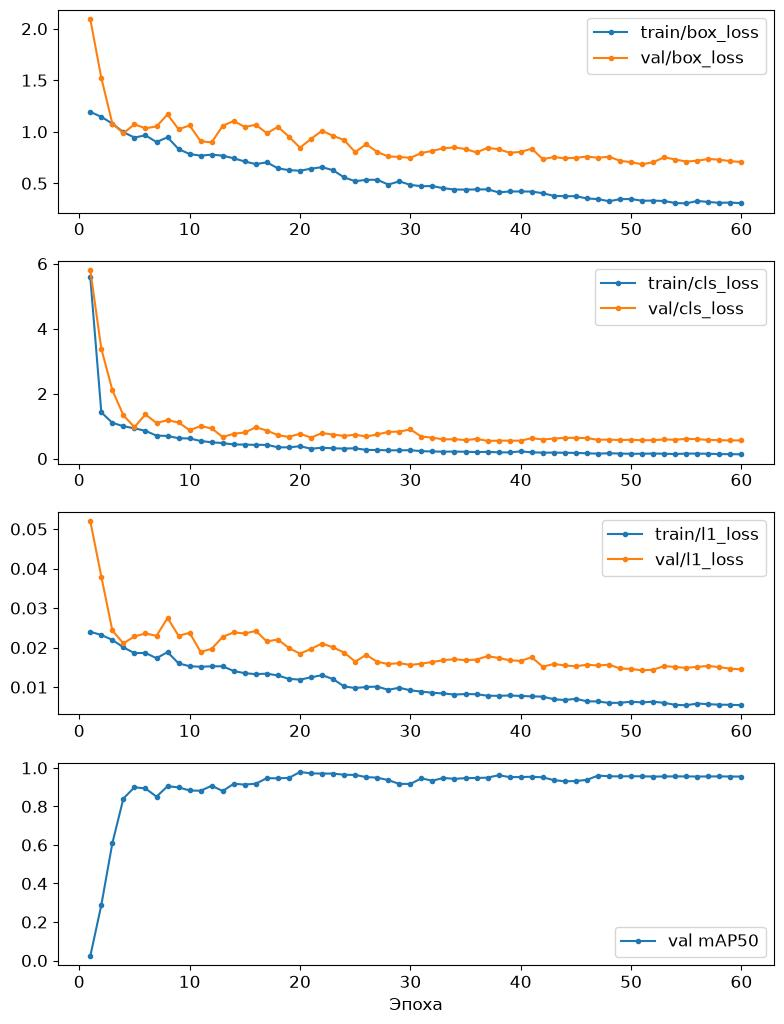

Лучший val mAP50 0.9787 на эпохе 20; время 1339.1 с, mps.
train/box_loss: разница среднего последней и первой трети, train -0.4992, val -0.3656
train/cls_loss: разница среднего последней и первой трети, train -0.7348, val -0.7773
train/l1_loss: разница среднего последней и первой трети, train -0.0103, val -0.0095


In [22]:
# ваш код
history = read_results(run_dir)
losses = [name for name in history if name.startswith('train/') and 'loss' in name
          and name.replace('train/', 'val/', 1) in history]
fig, axes = plt.subplots(len(losses) + 1, 1, figsize=(8, 2.6 * (len(losses) + 1)), squeeze=False)
for ax, name in zip(axes.flat, losses):
    for key in (name, name.replace('train/', 'val/', 1)):
        ax.plot(history['epoch'], history[key], marker='.', label=key)
    ax.legend()
map_key = next(key for key in history if key.startswith('metrics/mAP50('))
axes[-1, 0].plot(history['epoch'], history[map_key], marker='.', label='val mAP50')
axes[-1, 0].legend()
axes[-1, 0].set_xlabel('Эпоха')
plt.tight_layout()
plt.show()

peak_epoch = int(history['epoch'][np.argmax(history[map_key])])
print(f'Лучший val mAP50 {max(history[map_key]):.4f} на эпохе {peak_epoch}; '
      f'время {RUN_TIMES["train"]:.1f} с, {DEVICE_NAME}.')
for key in losses:
    val_key = key.replace('train/', 'val/', 1)
    count = max(1, len(history[key]) // 3)
    train_change = np.mean(history[key][-count:]) - np.mean(history[key][:count])
    val_change = np.mean(history[val_key][-count:]) - np.mean(history[val_key][:count])
    print(f'{key}: разница среднего последней и первой трети, train {train_change:+.4f}, val {val_change:+.4f}')

**Ответ.** Обучала с AdamW и lr = 0.001, чтобы адаптировать предобученные веса, при batch = 16 и размере 640×640, чтобы сохранять детали небольших голов. Использовала отражение по горизонтали, сдвиг и масштабирование. За 60 эпох на MPS ушло 22.3 мин, а `patience = 12` раньше прогон не остановил. На графике mAP50 вырос с 0.0227 до 0.9787 на двадцатой эпохе, а лучший mAP50–95 (0.7827) получился на пятидесятой, то есть после двадцатой эпохи ещё улучшалась точность рамок на строгих IoU. Train и val box/cls loss в среднем снизились, устойчивого роста val loss не видно. При отдельной оценке `best.pt` mAP50 на val составил 0.9545.

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [23]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

Ultralytics 8.4.216 🚀 Python-3.12.14 torch-2.15.0 MPS (Apple M4)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2443.2±1442.9 MB/s, size: 82.9 KB)
val: Scanning /Users/lizadyachkova/yolo-hw2/data/yolo/labels/val.cache... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 139.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.2it/s 1.7s0.3s
                   all        100        100      0.899       0.93      0.955      0.782
Speed: 0.2ms preprocess, 8.9ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /Users/lizadyachkova/yolo-hw2/runs_hw2/final_val
val {'map50': 0.9545323147476483, 'map50_95': 0.7815463467933226, 'precision': 0.8988785984058596, 'recall': 0.9299999999999999, 'per_class': {'cat_head': {'precision': 0.9269223241576483, 'recall': 0.98, 'map50': 0.9920279720279721, 'map50_95': 0

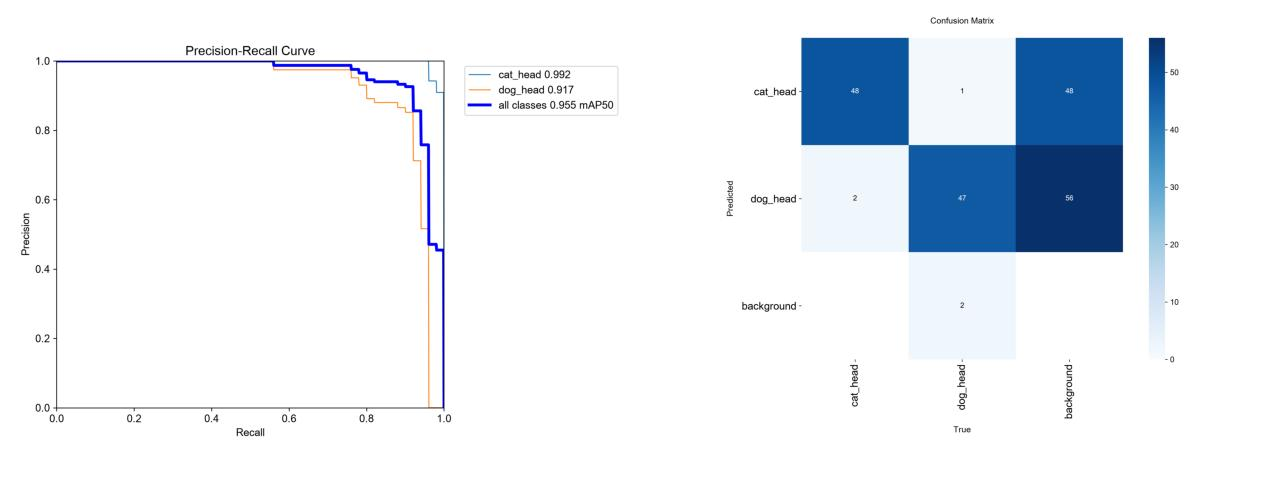

Ultralytics 8.4.216 🚀 Python-3.12.14 torch-2.15.0 MPS (Apple M4)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 234.9±66.6 MB/s, size: 88.2 KB)
val: Scanning /Users/lizadyachkova/yolo-hw2/data/yolo/labels/test... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 6.5Kit/s 0.0s
val: New cache created: /Users/lizadyachkova/yolo-hw2/data/yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.1it/s 1.7s0.2s
                   all        100        100       0.96      0.949      0.966      0.813
Speed: 0.2ms preprocess, 10.1ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /Users/lizadyachkova/yolo-hw2/runs_hw2/final_test
test {'map50': 0.9664188893561099, 'map50_95': 0.8132569291856442, 'precision': 0.9595112264333978, 'recall': 0.9488681609102809, 'per_class': {'cat_head': {'precision': 0.9

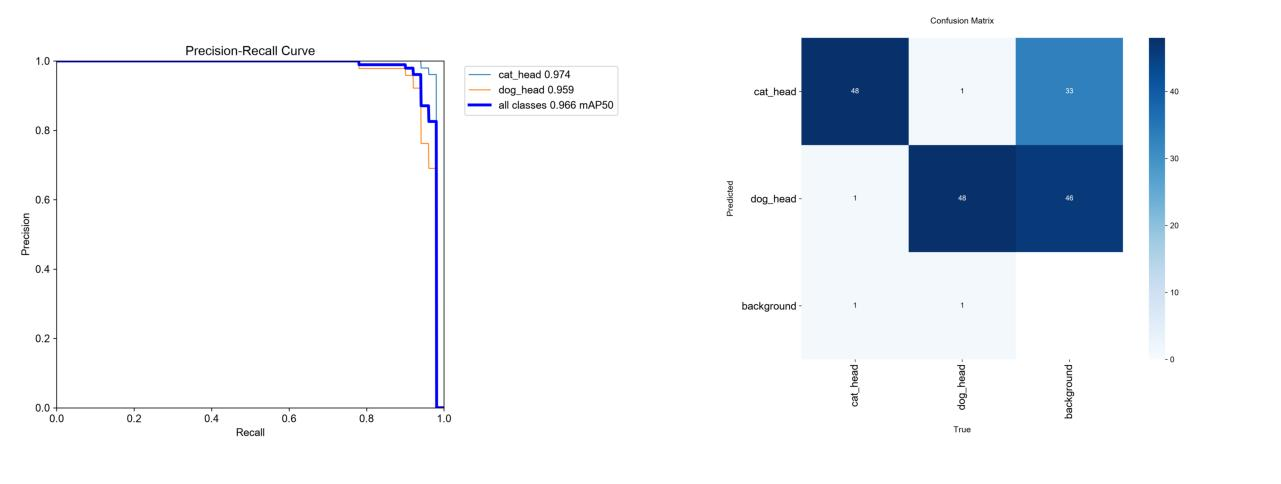

Сверка mAP50: 0.9514, разница с Ultralytics -0.0150


In [24]:
# ваш код
def summarize_metrics(metrics):
    box = metrics.box
    per_class = {}
    for row, label in enumerate(box.ap_class_index):
        p, r, ap50, ap = box.class_result(row)
        per_class[CLASSES[int(label)]] = dict(precision=float(p), recall=float(r),
                                             map50=float(ap50), map50_95=float(ap))
    return dict(map50=float(box.map50), map50_95=float(box.map),
                precision=float(box.mp), recall=float(box.mr), per_class=per_class)

validation = {}
for split in dict.fromkeys(('val', FINAL_SPLIT)):
    started = time.perf_counter()
    result = val_metrics(best, split, f'final_{split}', conf=0.001, plots=True)
    RUN_TIMES[f'final_{split}'] = time.perf_counter() - started
    validation[split] = summarize_metrics(result)
    print(split, validation[split])
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, suffix in zip(axes, ('PR_curve.png', 'confusion_matrix.png')):
        candidates = sorted(result.save_dir.glob(f'*{suffix}'))
        if candidates:
            ax.imshow(plt.imread(candidates[0]))
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

FINAL = dict(validation[FINAL_SPLIT], split=FINAL_SPLIT)
final_predictions = predict_records(best, records[FINAL_SPLIT], batch=BATCH)
FINAL['map50_custom'], _ = evaluate_map50(final_predictions, records[FINAL_SPLIT], len(CLASSES))
print(f"Сверка mAP50: {FINAL['map50_custom']:.4f}, разница с Ultralytics "
      f"{FINAL['map50_custom'] - FINAL['map50']:+.4f}")

In [25]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'map50': 0.9664,
 'map50_95': 0.8133,
 'precision': 0.9595,
 'recall': 0.9489,
 'split': 'test',
 'map50_custom': 0.9514}

**Ответ.** На val получились mAP50 = 0.9545, mAP50–95 = 0.7815, P = 0.8989 и R = 0.9300, на test 0.9664, 0.8133, 0.9595 и 0.9489. На test у собак AP50 почти такой же, как у кошек (0.9590 и 0.9738), но при усреднении по IoU разница больше (0.7521 и 0.8744). По примерам видно, что рамка собаки иногда захватывает часть корпуса, а на строгом IoU это сильнее снижает AP. В матрице строка background отвечает за пропуски размеченных объектов, а столбец background за боксы без пары в разметке. Свой mAP50 равен 0.9514, на 0.0150 ниже Ultralytics. Разница может возникать из-за сопоставления боксов и способа интегрирования PR-кривой.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [26]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    # ваш код
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)
    top_left = np.maximum(a[:, None, :2], b[None, :, :2])
    bottom_right = np.minimum(a[:, None, 2:], b[None, :, 2:])
    intersection = np.maximum(bottom_right - top_left, 0).prod(axis=-1)
    area_a = np.maximum(a[:, 2:] - a[:, :2], 0).prod(axis=-1)
    area_b = np.maximum(b[:, 2:] - b[:, :2], 0).prod(axis=-1)
    union = area_a[:, None] + area_b[None, :] - intersection
    return np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    # ваш код
    ious = box_iou_np(pred['boxes'], gt['boxes'])
    gt_labels = np.asarray(gt['labels'])
    true_positives = np.zeros(len(gt_labels), dtype=bool)
    associated = np.zeros(len(gt_labels), dtype=bool)
    categories = ['background'] * len(pred['labels'])

    for index in np.argsort(-np.asarray(pred['scores']), kind='stable'):
        same_class = gt_labels == pred['labels'][index]
        overlap = ious[index]
        candidates = (
            ('tp', same_class & ~true_positives & (overlap >= iou_hit)),
            ('class', ~same_class & (overlap >= iou_hit)),
            ('localization', same_class & ~true_positives & (overlap >= iou_loc) & (overlap < iou_hit)),
        )
        for category, mask in candidates:
            eligible = np.flatnonzero(mask)
            if eligible.size:
                match = eligible[overlap[eligible].argmax()]
                categories[index] = category
                associated[match] = True
                if category == 'tp':
                    true_positives[match] = True
                break
    return categories, np.flatnonzero(~associated).tolist()

In [27]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


tp: 93 (90.3%) {'cat_head': 48, 'dog_head': 45}
class: 4 (3.9%) {'cat_head': 1, 'dog_head': 3}
localization: 3 (2.9%) {'cat_head': 0, 'dog_head': 3}
background: 1 (1.0%) {'cat_head': 1, 'dog_head': 0}
missed: 2 (1.9%) {'cat_head': 0, 'dog_head': 2}


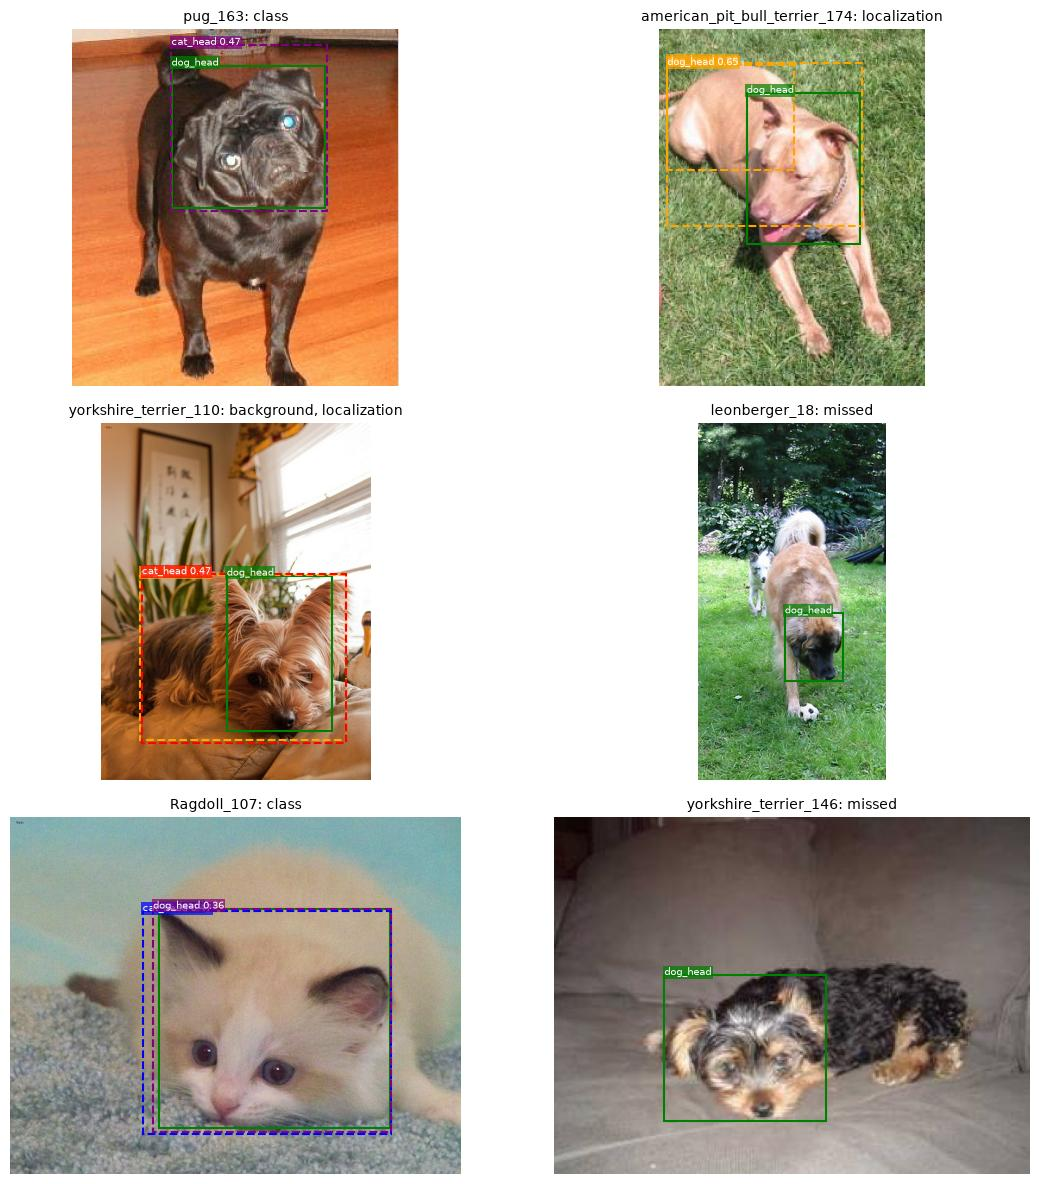

Самая частая ошибка: class, 4 из 10 (40.0%).


In [28]:
# ваш код
val_records = records['val']
error_predictions = predict_records(best, val_records, conf=CONF_ERRORS, batch=BATCH)
ERRORS = dict.fromkeys(ERROR_TYPES, 0)
by_class = {name: dict.fromkeys(ERROR_TYPES, 0) for name in CLASSES}
examples = {category: [] for category in ERROR_TYPES if category != 'tp'}

for index, (prediction, record) in enumerate(zip(error_predictions, val_records)):
    categories, missed = categorize_predictions(prediction, record)
    counts = Counter(categories)
    counts['missed'] = len(missed)
    for category in ERROR_TYPES:
        ERRORS[category] += counts[category]
    for category, label in zip(categories, prediction['labels']):
        by_class[CLASSES[label]][category] += 1
    for gt_index in missed:
        by_class[CLASSES[record['labels'][gt_index]]]['missed'] += 1
    for category in examples:
        if counts[category]:
            examples[category].append((index, categories))

total_events = max(1, sum(ERRORS.values()))
for category, count in ERRORS.items():
    print(f'{category}: {count} ({count / total_events:.1%})',
          {name: counts[category] for name, counts in by_class.items()})

selected = {}
for rank in range(6):
    for example_list in examples.values():
        if rank < len(example_list):
            index, categories = example_list[rank]
            selected.setdefault(index, categories)
        if len(selected) >= 6:
            break
    if len(selected) >= 6:
        break

if selected:
    fig, axes = plt.subplots(math.ceil(len(selected) / 2), 2,
                             figsize=(12, 4 * math.ceil(len(selected) / 2)), squeeze=False)
    for ax in axes.flat:
        ax.set_axis_off()
    for ax, (index, categories) in zip(axes.flat, selected.items()):
        record, prediction = val_records[index], error_predictions[index]
        _, missed = categorize_predictions(prediction, record)
        title = ', '.join(sorted(set(categories) - {'tp'} | ({'missed'} if missed else set())))
        with Image.open(record['image']) as image:
            draw_boxes(ax, image.convert('RGB'), record['boxes'], record['labels'], CLASSES,
                       color='green', title=f"{Path(record['image']).stem}: {title}")
        for category, color in [('tp', 'blue'), ('class', 'purple'),
                                ('localization', 'orange'), ('background', 'red')]:
            candidates = np.flatnonzero(np.asarray(categories, dtype=str) == category)
            ranked = candidates[np.argsort(-prediction['scores'][candidates])[:3]]
            draw_boxes(ax, None, prediction['boxes'][ranked], prediction['labels'][ranked],
                       CLASSES, prediction['scores'][ranked], color=color, linestyle='--')
    plt.tight_layout()
    plt.show()

error_only = {name: count for name, count in ERRORS.items() if name != 'tp'}
worst_error = max(error_only, key=error_only.get)
number_errors = sum(error_only.values())
if number_errors:
    print(f'Самая частая ошибка: {worst_error}, {error_only[worst_error]} из {number_errors} '
          f'({error_only[worst_error] / number_errors:.1%}).')
else:
    print('При этом пороге ошибки по заданным категориям не обнаружены.')

**Ответ.** При conf ≥ 0.25 на val получилось 93 верных детекции и 10 ошибок (4 ошибки класса, 3 ошибки локализации, 1 лишний бокс и 2 пропуска). Чаще всего модель путала классы (40% ошибок). Например, у `pug_163` бокс почти совпал с разметкой, но мопс определился как кошка. У `american_pit_bull_terrier_174` рамка захватила корпус, а у `leonberger_18` размеченная голова пропущена. Разметка основной головы на этих примерах выглядит корректной. Я бы добавила в train больше ракурсов пород, на которых модель путает классы.

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [29]:
# ваш код
freeze_layers = len(arch.yaml['backbone'])
_, RUN_TIMES['ablation'], ablation_dir = train_yolo('freeze_backbone', **dict(TRAIN_ARGS, freeze=freeze_layers))
frozen = YOLO(ablation_dir / 'weights' / 'best.pt')
frozen_val = summarize_metrics(val_metrics(frozen, 'val', 'freeze_val', conf=0.001, plots=False))
ABLATION = dict(parameter='freeze',
                baseline=dict(value=0, map50=validation['val']['map50'],
                              map50_95=validation['val']['map50_95'], time_sec=RUN_TIMES['train']),
                variant=dict(value=freeze_layers, map50=frozen_val['map50'],
                             map50_95=frozen_val['map50_95'], time_sec=RUN_TIMES['ablation']))
print(ABLATION)

delta_ap = ABLATION['variant']['map50'] - ABLATION['baseline']['map50']
delta_time = RUN_TIMES['ablation'] - RUN_TIMES['train']
worst_class = min(FINAL['per_class'], key=lambda name: FINAL['per_class'][name]['map50']) if FINAL['per_class'] else None
class_sentence = (f"Минимальный AP50 на {FINAL_SPLIT} получился у {worst_class}: "
                  f"{FINAL['per_class'][worst_class]['map50']:.4f}. " if worst_class else '')
if worst_error == 'localization':
    next_step = 'Дальше проверю локализацию отдельно для маленьких голов и увеличу разрешение входа в следующем эксперименте.'
elif worst_error == 'class':
    next_step = 'Дальше посмотрю примеры путаницы классов по породам и добавлю похожие ракурсы в обучающую выборку.'
elif worst_error == 'background':
    next_step = 'Дальше проверю ложные срабатывания и дубли на размеченных примерах и подберу порог уверенности по val.'
else:
    next_step = 'Дальше сравню полноту по размеру и ракурсу головы, чтобы понять, какие примеры добавить в train.'
mode = 'Отладочный прогон' if FAST_MODE else 'Полный прогон'
display(Markdown(
    f"**{mode}.** На {FINAL_SPLIT} COCO дал mAP50 {coco_map50:.4f}, "
    f"а эвристика по train — {heuristic_map50:.4f}. "
    f"После дообучения mAP50 составил {FINAL['map50']:.4f}, "
    f"mAP50–95 — {FINAL['map50_95']:.4f}. "
    + class_sentence
    + f"На val заморозка backbone изменила mAP50 на {delta_ap:+.4f} "
    f"и время обучения на {delta_time:+.1f} с. "
    f"Оценка основана на одном seed, {len(records['val'])} val и {len(records['test'])} test изображениях. "
    + next_step
))

Ultralytics 8.4.216 🚀 Python-3.12.14 torch-2.15.0 MPS (Apple M4)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=11, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=freeze_backbone, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, overla

/Users/lizadyachkova/yolo-hw2/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/60      4.23G      1.152      5.673    0.02327         16        640: 100% ━━━━━━━━━━━━ 25/25 1.8it/s 13.6s0.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.1it/s 1.9s0.8s
                   all        100        100       0.58      0.187      0.322      0.193

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/60      3.22G     0.9423      1.539    0.01582         16        640: 0% ──────────── 0/25  0.6s

/Users/lizadyachkova/yolo-hw2/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/60      4.23G      1.058      1.321    0.02133         16        640: 100% ━━━━━━━━━━━━ 25/25 1.9it/s 13.3s0.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.2it/s 1.8s0.8s
                   all        100        100      0.729      0.755      0.774      0.468

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/60      3.23G     0.8445      1.143    0.01817         16        640: 0% ──────────── 0/25  0.6s

/Users/lizadyachkova/yolo-hw2/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (112 outputs left out)

      59/60      4.24G     0.2999     0.1407   0.005345         16        640: 100% ━━━━━━━━━━━━ 25/25 1.9it/s 13.2s0.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.2it/s 1.8s0.8s
                   all        100        100      0.933      0.917      0.976      0.795

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      60/60      3.24G     0.4264      0.145    0.01042         16        640: 0% ──────────── 0/25  0.6s

/Users/lizadyachkova/yolo-hw2/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      60/60      4.24G     0.3174       0.16   0.005711         16        640: 100% ━━━━━━━━━━━━ 25/25 1.9it/s 13.2s0.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.2it/s 1.8s0.8s
                   all        100        100      0.934      0.917      0.976      0.793

60 epochs completed in 0.273 hours.
Optimizer stripped from /Users/lizadyachkova/yolo-hw2/runs_hw2/freeze_backbone/weights/last.pt, 5.4MB
Optimizer stripped from /Users/lizadyachkova/yolo-hw2/runs_hw2/freeze_backbone/weights/best.pt, 5.4MB

Validating /Users/lizadyachkova/yolo-hw2/runs_hw2/freeze_backbone/weights/best.pt...
Ultralytics 8.4.216 🚀 Python-3.12.14 torch-2.15.0 MPS (Apple M4)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.8it/s 1.4s0.6s
                   all        100        100      0.955  

**Полный прогон.** На test COCO дал mAP50 0.0808, а эвристика по train — 0.0372. После дообучения mAP50 составил 0.9664, mAP50–95 — 0.8133. Минимальный AP50 на test получился у dog_head: 0.9590. На val заморозка backbone изменила mAP50 на +0.0220 и время обучения на -351.6 с. Оценка основана на одном seed, 100 val и 100 test изображениях. Дальше посмотрю примеры путаницы классов по породам и добавлю похожие ракурсы в обучающую выборку.

**Ответ.** При заморозке 11 слоёв mAP50 на val вырос с 0.9545 до 0.9766 (+0.0220), mAP50–95 — с 0.7815 до 0.8039. Время уменьшилось с 22.3 до 16.5 мин (около 26%), потому что градиенты по backbone не вычисляются. Для этой выборки заморозка оказалась выгодна по времени и по качеству. Возможно, признаков COCO достаточно для такого небольшого датасета. Чтобы проверить устойчивость результата, я бы повторила сравнение на нескольких seed.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ.** До дообучения COCO-модель дала mAP50 0.0808 на test, а эвристика по медианной рамке 0.0372. После обучения на 400 снимках mAP50 вырос до 0.9664, а mAP50–95 составил 0.8133. На строгих порогах IoU хуже получались рамки собак. Среди 10 ошибок на val чаще всего встречалась путаница классов (4 случая). Заморозка backbone повысила mAP50 на val до 0.9766 и сэкономила около 5.9 мин. Эксперимент сделан с одним seed, по 100 снимков на val и test и одной размеченной головой на фото. Дальше я бы повторила абляцию на нескольких seed и проверила модель на кадрах с несколькими животными.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [31]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ.** Этот бонус не выполнялся. Для него нужна ручная разметка от 50 новых снимков.

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [32]:
if '6.2' in BONUS_TASKS:
    # ваш код
    from ultralytics import RTDETR

    detector = RTDETR('rtdetr-l.pt')
    transformer_params = sum(parameter.numel() for parameter in detector.model.parameters())
    transformer_args = dict(TRAIN_ARGS, batch=min(BATCH, 4))
    start = time.perf_counter()
    detector.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS,
                   project=str(RUNS.resolve()), name='rtdetr', exist_ok=True,
                   verbose=False, **transformer_args)
    transformer_time = time.perf_counter() - start
    transformer_best = RTDETR(Path(detector.trainer.save_dir) / 'weights' / 'best.pt')
    transformer_val = summarize_metrics(transformer_best.val(
        data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=transformer_args['batch'],
        device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name='rtdetr_val',
        exist_ok=True, verbose=False, conf=0.001, plots=False))
    image_path = str(records['val'][0]['image'])
    architecture_comparison = {}
    yolo_candidate = YOLO(run_dir / 'weights' / 'best.pt')
    models = [
        ('YOLO26n', yolo_candidate, MODEL_INFO['params'], RUN_TIMES['train'], validation['val']),
        ('RT-DETR-L', transformer_best, transformer_params, transformer_time, transformer_val),
    ]
    for name, candidate, parameters, seconds, metrics in models:
        settings = dict(imgsz=IMGSZ, device=DEVICE, verbose=False, rect=False)
        for _ in range(3):
            candidate.predict(image_path, **settings)
        sync_device()
        start = time.perf_counter()
        for _ in range(12):
            candidate.predict(image_path, **settings)
            sync_device()
        architecture_comparison[name] = dict(
            params=parameters, train_sec=seconds, latency_ms=(time.perf_counter() - start) * 1000 / 12,
            map50=metrics['map50'], map50_95=metrics['map50_95'])
    print(json.dumps(architecture_comparison, indent=2))

**Ответ.** Код сравнения с RT-DETR-L подготовлен. Обучение RT-DETR не запускалось, поэтому сравнить время, задержку и качество по этому прогону нельзя.

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [33]:
if '6.3' in BONUS_TASKS:
    # ваш код
    import yaml

    shift_root = (DATA_ROOT / 'domain_shift').resolve()
    shift_rng = np.random.default_rng(SEED)
    shift_model = YOLO(run_dir / 'weights' / 'best.pt')
    shifts = {}
    for shift in ('dark', 'noise', 'jpeg'):
        target = shift_root / shift
        image_dir = target / 'images' / 'val'
        label_dir = target / 'labels' / 'val'
        image_dir.mkdir(parents=True, exist_ok=True)
        label_dir.mkdir(parents=True, exist_ok=True)
        for path in sorted((YOLO_ROOT / 'images' / 'val').glob('*.jpg')):
            with Image.open(path) as original:
                image = original.convert('RGB')
                pixels = np.asarray(image, dtype=np.float32)
            if shift == 'dark':
                image = Image.fromarray((pixels * 0.35).astype(np.uint8))
            elif shift == 'noise':
                noise = shift_rng.normal(0, 30, pixels.shape)
                image = Image.fromarray(np.clip(pixels + noise, 0, 255).astype(np.uint8))
            image.save(image_dir / path.name, quality=8 if shift == 'jpeg' else 95)
            label = f'{path.stem}.txt'
            shutil.copy2(YOLO_ROOT / 'labels' / 'val' / label, label_dir / label)
        config = yaml.safe_load(DATA_YAML.read_text())
        config.update(path=str(target), val='images/val',
                      train=str((YOLO_ROOT / 'images' / 'train').resolve()))
        config.pop('test', None)
        shift_yaml = target / 'data.yaml'
        shift_yaml.write_text(yaml.safe_dump(config), encoding='utf-8')
        shifts[shift] = summarize_metrics(shift_model.val(
            data=str(shift_yaml), split='val', imgsz=IMGSZ, batch=BATCH,
            device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()),
            name=f'shift_{shift}', exist_ok=True, verbose=False, plots=False, conf=0.001))
    print(json.dumps({'clean': validation['val'], **shifts}, indent=2))

Ultralytics 8.4.216 🚀 Python-3.12.14 torch-2.15.0 MPS (Apple M4)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1013.5±498.4 MB/s, size: 28.8 KB)
val: Scanning /Users/lizadyachkova/yolo-hw2/data/domain_shift/dark/labels/val... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 4.3Kit/s 0.0s
val: New cache created: /Users/lizadyachkova/yolo-hw2/data/domain_shift/dark/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 6.5it/s 1.1s0.2s
                   all        100        100      0.935      0.945      0.969       0.78
Speed: 0.2ms preprocess, 5.0ms inference, 0.0ms loss, 2.0ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.12.14 torch-2.15.0 MPS (Apple M4)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3427.0±1251.1 MB/

**Ответ.** На чистом val mAP50 / mAP50–95 равны 0.9545 / 0.7815, после затемнения 0.9687 / 0.7798, после шума 0.4932 / 0.3513, после JPEG (quality = 8) равен 0.4827 / 0.3323. Сильнее всего повлияло JPEG-сжатие, особенно на собак: их AP50 упал с 0.9170 до 0.2497, а у кошек с 0.9920 до 0.7157. Сжатие убирает мелкие детали и даёт артефакты на границах. Я бы проверила, поможет ли случайное JPEG-сжатие и добавление шума на train.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [34]:
if '6.4' in BONUS_TASKS:
    # ваш код
    import tempfile

    with tempfile.TemporaryDirectory() as temporary:
        export_weights = Path(temporary) / 'best.pt'
        shutil.copy2(run_dir / 'weights' / 'best.pt', export_weights)
        onnx_path = YOLO(export_weights).export(
            format='onnx', imgsz=IMGSZ, device='cpu', dynamic=True,
            simplify=False, nms=False, half=False)
        torch_model = YOLO(export_weights)
        onnx_model = YOLO(onnx_path, task='detect')
        paths = [str(path) for path in sorted((YOLO_ROOT / 'images' / 'val').glob('*.jpg'))[:20]]
        export_comparison = {}
        for name, candidate in [('PyTorch', torch_model), ('ONNX Runtime', onnx_model)]:
            predict_kwargs = dict(imgsz=IMGSZ, device='cpu', verbose=False, rect=False)
            for path in paths[:5]:
                candidate.predict(path, **predict_kwargs)
            start = time.perf_counter()
            for path in paths:
                candidate.predict(path, **predict_kwargs)
            elapsed_ms = (time.perf_counter() - start) * 1000 / len(paths)
            result = candidate.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ,
                                   batch=1, device='cpu', workers=0, conf=0.001, rect=False, nms=False,
                                   project=str(RUNS.resolve()), name='export_val',
                                   exist_ok=True, verbose=False, plots=False)
            export_comparison[name] = dict(latency_ms=elapsed_ms, map50=float(result.box.map50),
                                           map50_95=float(result.box.map))
        export_dir = RUNS / 'onnx'
        export_dir.mkdir(parents=True, exist_ok=True)
        shutil.copy2(onnx_path, export_dir / 'best.onnx')
        print(json.dumps(export_comparison, indent=2))

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.216 🚀 Python-3.12.14 torch-2.15.0 CPU (Apple M4)
YOLO26n summary (fused): 122 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/var/folders/r_/m1r8r5kd2tl1hh1lgw8c9tx40000gn/T/tmp7zbdqb84/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 300, 6) (5.2 MB)
requirements: Ultralytics requirement ['onnx>=1.12.0,<2.0.0'] not found, attempting AutoUpdate...
Resolved 5 packages in 13.05s
 Downloaded onnx
Prepared 3 packages in 7.57s
Installed 3 packages in 22ms
 + ml-dtypes==0.7.0
 + onnx==1.23.2
 + protobuf==7.36.2

requirements: AutoUpdate success ✅ 20.9s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: export success ✅ 22.7s, saved as '/var/folders/r_/m1r8r5kd2tl1hh1lgw8c9tx40000gn/T/tmp7zbdqb84/best.onnx' (9.2 MB)

Export complete (22.9s)
R

**Ответ.** На CPU Apple M4 при размере 640×640 и batch = 1 PyTorch занял 36.61 мс на фото, ONNX Runtime — 23.86 мс (ускорение 1.53×). У обеих версий при одинаковой подготовке изображений и выключенном NMS mAP50 = 0.9259 и mAP50–95 = 0.7685. ONNX Runtime выполняет экспортированный граф оптимизированными CPU-операторами, и в нашем замере выигрыш по времени получился без потери качества. Для повторного запуска нужны `onnx` и `onnxruntime`.

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [35]:
if '6.5' in BONUS_TASKS:
    # ваш код
    threshold_results = []
    for use_nms in (False, True):
        for conf in (0.001, 0.10, 0.25, 0.50):
            for iou in (0.35, 0.65):
                threshold_model = YOLO(run_dir / 'weights' / 'best.pt')
                result = val_metrics(threshold_model, 'val', 'threshold_grid', nms=use_nms,
                                     conf=conf, iou=iou, plots=True)
                matrix = result.confusion_matrix.matrix
                hits = np.trace(matrix[:-1, :-1])
                precision = hits / max(1, matrix[:-1, :].sum())
                recall = hits / max(1, matrix[:, :-1].sum())
                threshold_results.append(dict(nms=use_nms, conf=conf, iou=iou,
                                              precision=float(precision), recall=float(recall),
                                              map50=float(result.box.map50), map50_95=float(result.box.map)))
    print(json.dumps(threshold_results, indent=2))

Ultralytics 8.4.216 🚀 Python-3.12.14 torch-2.15.0 MPS (Apple M4)
YOLO26n summary (fused): 122 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4321.2±1160.1 MB/s, size: 130.9 KB)
val: Scanning /Users/lizadyachkova/yolo-hw2/data/yolo/labels/val.cache... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 104.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 5.7it/s 1.2s0.2s
                   all        100        100      0.938      0.863       0.93      0.765
Speed: 0.6ms preprocess, 5.4ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /Users/lizadyachkova/yolo-hw2/runs_hw2/threshold_grid
Ultralytics 8.4.216 🚀 Python-3.12.14 torch-2.15.0 MPS (Apple M4)
YOLO26n summary (fused): 122 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1612.2±1089.3 MB/s, size: 47.4 KB)
val: Sca

**Ответ.** Для end-to-end выбрала бы conf = 0.10 (P = 0.8214, R = 0.9200). При conf = 0.50 precision выше (0.9643), но recall падает до 0.8100. Переход от IoU 0.35 к 0.65 в end-to-end ничего не изменил, потому что там нет NMS. В ветке с NMS при conf = 0.10 порог IoU 0.35 дал P = 0.8774 против 0.8611 при одинаковом R = 0.9300. AP учитывает порядок предсказаний на всей PR-кривой, а P и R считаются при конкретной отсечке. Если отсечку поднять слишком высоко, часть верных боксов убирается и AP тоже падает (здесь с 0.9295 до 0.7975).